### Problem 15 : VQE - finding the ground state of a molecule

So far every variational circuit we trained was a **classifier**. But the very first application
people expect quantum computers to be genuinely useful for is not classification - it is
**simulating quantum systems**, and specifically **chemistry**.

The reason is simple. To store the wavefunction of a molecule with n spin-orbitals classically you
need 2ⁿ numbers. Forty orbitals - a small molecule - is already a trillion trillion amplitudes. A
quantum computer stores that state in n qubits, because it *is* a quantum system.

The **Variational Quantum Eigensolver** (VQE) is the algorithm that exploits this, and structurally
it is *exactly* the hybrid loop from Problem 10 with the loss function swapped out :

| | VQC (Problem 10) | VQE (here) |
|---|---|---|
| circuit | feature map + ansatz | chemistry-inspired ansatz |
| measured quantity | ⟨Z⟩ | ⟨H⟩, the molecular Hamiltonian |
| loss | squared error vs labels | **the energy itself** |
| optimizer | Adam | Adam / gradient descent |
| answer | a decision boundary | the **ground state energy** |

**Why minimising energy is guaranteed to be meaningful** - the *variational principle* :

**⟨ψ(θ)∣H∣ψ(θ)⟩ ≥ E₀   for every θ**

The expectation value of the Hamiltonian in *any* state is at least the true ground state energy.
So we can never overshoot : lower is always strictly better, and we get a rigorous upper bound on
E₀ for free. There is no equivalent guarantee in machine learning.

**TASK :** Compute the ground state energy of the hydrogen molecule H₂, and map out its full
dissociation curve.

📄 Original paper : https://www.nature.com/articles/ncomms5213

In [1]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt

#### Step 1 : Get the molecular Hamiltonian

`qml.qchem.molecular_hamiltonian` does the classical chemistry for us : it solves the Hartree-Fock
problem in a minimal (STO-3G) basis, computes the one- and two-electron integrals, and maps the
resulting fermionic Hamiltonian onto qubits (Jordan-Wigner by default).

The output is a plain **sum of Pauli strings** :

**H = Σᵢ cᵢ · Pᵢ**  where each Pᵢ is something like Z₀Z₁ or X₀Y₁Y₂X₃

Every one of those terms is an observable we know how to measure.

> **Units.** Coordinates are in **Bohr** and energies in **Hartree**. 1 Bohr ≈ 0.529 Å,
> 1 Hartree ≈ 27.2 eV. The H₂ bond length is about 1.32 Bohr = 0.74 Å.

In [2]:
symbols = ["H", "H"]
bond_length = 1.3228                     # Bohr - the experimental equilibrium distance

coordinates = np.array([0.0, 0.0, -bond_length / 2,
                        0.0, 0.0,  bond_length / 2])

H, n_qubits = qml.qchem.molecular_hamiltonian(symbols, coordinates)

print("Qubits needed        :", n_qubits)
print("Pauli terms in H     :", len(H.terms()[0]))
print()
print(H)

Qubits needed        : 4
Pauli terms in H     : 15

-0.04207255194743914 * I([0, 1, 2, 3]) + 0.1777135822909175 * Z(0) + 0.1777135822909175 * Z(1) + 0.17059759276836803 * (Z(0) @ Z(1)) + -0.2427450126094143 * Z(2) + 0.12293330449299361 * (Z(0) @ Z(2)) + 0.16768338855601356 * (Z(1) @ Z(2)) + 0.044750084063019925 * (Y(0) @ X(1) @ X(2) @ Y(3)) + -0.044750084063019925 * (Y(0) @ Y(1) @ X(2) @ X(3)) + -0.044750084063019925 * (X(0) @ X(1) @ Y(2) @ Y(3)) + 0.044750084063019925 * (X(0) @ Y(1) @ Y(2) @ X(3)) + -0.2427450126094143 * Z(3) + 0.16768338855601356 * (Z(0) @ Z(3)) + 0.12293330449299361 * (Z(1) @ Z(3)) + 0.1762766139418181 * (Z(2) @ Z(3))


Four qubits : two electrons in two spatial orbitals gives four spin-orbitals, and Jordan-Wigner
uses one qubit per spin-orbital. Qubit i being ∣1⟩ means "spin-orbital i is occupied".

#### Step 2 : The reference state and the ansatz

We start from the **Hartree-Fock state** - the best possible *single-configuration* guess, where the
two electrons simply fill the two lowest spin-orbitals : ∣1100⟩. That is where classical chemistry's
cheapest method stops.

Everything HF misses is called **electron correlation**, and it comes from the electrons being in a
*superposition* of configurations. For H₂ the dominant missing piece is the double excitation where
both electrons jump to the higher orbital, ∣0011⟩. So the true ground state looks like

**∣ψ⟩ = cos(θ/2)·∣1100⟩ − sin(θ/2)·∣0011⟩**

and our ansatz needs exactly **one** parameter : `qml.DoubleExcitation(θ)`, which rotates between
those two configurations.

This is what a **problem-inspired ansatz** means, and it is the direct answer to Problem 12. We are
not stacking generic entangling layers and hoping - we are building the circuit out of the physics.
One parameter, no barren plateau, no local minima.

In [3]:
electrons = 2
hf_state = qml.qchem.hf_state(electrons, n_qubits)
print("Hartree-Fock reference state:", hf_state, " -> |1100>")

dev = qml.device("default.qubit", wires=n_qubits)


@qml.qnode(dev)
def energy(params):
    qml.BasisState(hf_state, wires=range(n_qubits))     # start from Hartree-Fock
    qml.DoubleExcitation(params[0], wires=[0, 1, 2, 3])  # mix in the double excitation
    return qml.expval(H)                                 # <- the loss IS the energy


print()
print(qml.draw(energy)(np.array([0.2])))

Hartree-Fock reference state: [1 1 0 0]  -> |1100>

0: ─╭|Ψ⟩─╭G²(0.20)─┤ ╭<𝓗>
1: ─├|Ψ⟩─├G²(0.20)─┤ ├<𝓗>
2: ─├|Ψ⟩─├G²(0.20)─┤ ├<𝓗>
3: ─╰|Ψ⟩─╰G²(0.20)─┤ ╰<𝓗>


In [4]:
# Step 3: Minimise the energy
params = np.array([0.0], requires_grad=True)     # theta = 0 means "pure Hartree-Fock"
opt = qml.GradientDescentOptimizer(stepsize=0.4)

print(f"Starting energy (Hartree-Fock): {energy(params):.8f} Ha")
print()

history = [float(energy(params))]
for step in range(30):
    params = opt.step(energy, params)
    history.append(float(energy(params)))
    if (step + 1) % 5 == 0:
        print(f"Step {step + 1:2d} | energy {history[-1]:.8f} Ha | theta {float(params[0]):.5f}")

Starting energy (Hartree-Fock): -1.11734892 Ha

Step  5 | energy -1.13590595 Ha | theta 0.18406
Step 10 | energy -1.13618498 Ha | theta 0.20661
Step 15 | energy -1.13618910 Ha | theta 0.20935
Step 20 | energy -1.13618916 Ha | theta 0.20969


Step 25 | energy -1.13618916 Ha | theta 0.20973


Step 30 | energy -1.13618916 Ha | theta 0.20973


#### Step 4 : Check the answer

H₂ in this basis is small enough that we can simply **diagonalise the Hamiltonian matrix** and get
the true ground state energy. On a real problem this is exactly what you cannot do - that is the
whole point - but on a 4-qubit toy it is the perfect way to validate the method.

The benchmark that matters in quantum chemistry is **chemical accuracy** : 1.6 mHa (1 kcal/mol),
roughly the precision needed to predict whether a reaction actually happens.

In [5]:
exact_energy = float(np.min(np.linalg.eigvalsh(qml.matrix(H))))
vqe_energy = history[-1]
hf_energy = history[0]

print(f"Hartree-Fock energy : {hf_energy:.8f} Ha")
print(f"VQE energy          : {vqe_energy:.8f} Ha")
print(f"Exact (diagonalised): {exact_energy:.8f} Ha")
print()
print(f"Correlation energy recovered by VQE: {hf_energy - vqe_energy:.6f} Ha")
print(f"VQE error vs exact                 : {abs(vqe_energy - exact_energy):.2e} Ha")
print(f"Chemical accuracy threshold        : 1.60e-03 Ha", )
print()
print("Within chemical accuracy?", abs(vqe_energy - exact_energy) < 1.6e-3)

Hartree-Fock energy : -1.11734892 Ha
VQE energy          : -1.13618916 Ha
Exact (diagonalised): -1.13618916 Ha

Correlation energy recovered by VQE: 0.018840 Ha
VQE error vs exact                 : 2.00e-13 Ha
Chemical accuracy threshold        : 1.60e-03 Ha

Within chemical accuracy? True


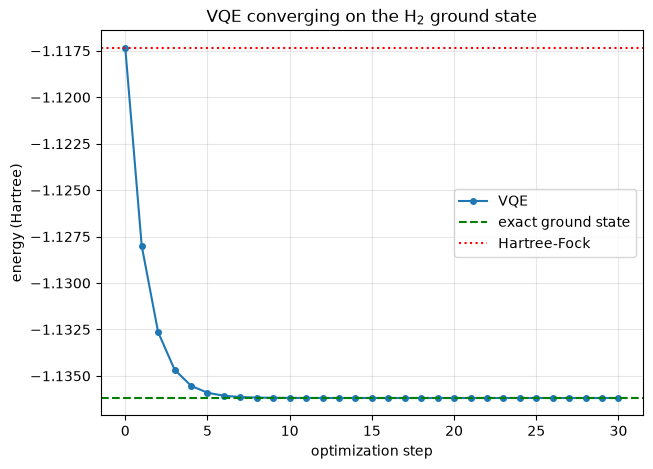

In [6]:
plt.figure(figsize=(7, 5))
plt.plot(history, 'o-', markersize=4, label='VQE')
plt.axhline(exact_energy, color='g', linestyle='--', label='exact ground state')
plt.axhline(hf_energy, color='r', linestyle=':', label='Hartree-Fock')
plt.xlabel("optimization step"); plt.ylabel("energy (Hartree)")
plt.title("VQE converging on the H$_2$ ground state")
plt.legend(); plt.grid(alpha=0.3); plt.show()

#### Step 5 : The dissociation curve

One energy is a number; a **curve** is chemistry. Let us repeat the whole calculation at a range of
bond lengths and watch the molecule form and then break apart.

This also exposes the single most important weakness of Hartree-Fock. Near equilibrium HF is quite
good. As you pull the atoms apart the true ground state becomes an equal mixture of ∣1100⟩ and
∣0011⟩ - a genuinely **multi-configurational** state - and a method that allows only one
configuration cannot describe it at all. This is called **static correlation**, and it is precisely
the regime where quantum algorithms are expected to earn their keep.

In [7]:
def run_vqe(r, steps=60):
    """Full VQE at bond length r, plus the HF and exact energies for comparison."""
    coords = np.array([0.0, 0.0, -r / 2, 0.0, 0.0, r / 2])
    H_r, n = qml.qchem.molecular_hamiltonian(symbols, coords)

    dev_r = qml.device("default.qubit", wires=n)
    hf = qml.qchem.hf_state(electrons, n)

    @qml.qnode(dev_r)
    def circuit(p):
        qml.BasisState(hf, wires=range(n))
        qml.DoubleExcitation(p[0], wires=[0, 1, 2, 3])
        return qml.expval(H_r)

    p = np.array([0.0], requires_grad=True)
    hf_e = float(circuit(p))                       # theta = 0 is exactly Hartree-Fock

    opt_r = qml.GradientDescentOptimizer(stepsize=0.4)
    for _ in range(steps):
        p = opt_r.step(circuit, p)

    exact_e = float(np.min(np.linalg.eigvalsh(qml.matrix(H_r))))
    return float(circuit(p)), hf_e, exact_e


distances = [0.5, 0.7, 0.9, 1.1, 1.3228, 1.6, 2.0, 2.5, 3.0]
vqe_curve, hf_curve, exact_curve = [], [], []

for r in distances:
    v, h, e = run_vqe(r)
    vqe_curve.append(v); hf_curve.append(h); exact_curve.append(e)
    print(f"r = {r:6.4f} Bohr | VQE {v:.6f} | HF {h:.6f} | exact {e:.6f} | HF error {h - e:.4f}")

r = 0.5000 Bohr | VQE -0.410788 | HF -0.403326 | exact -0.410788 | HF error 0.0075


r = 0.7000 Bohr | VQE -0.846326 | HF -0.837130 | exact -0.846326 | HF error 0.0092


r = 0.9000 Bohr | VQE -1.031043 | HF -1.019497 | exact -1.031043 | HF error 0.0115


r = 1.1000 Bohr | VQE -1.109137 | HF -1.094564 | exact -1.109137 | HF error 0.0146


r = 1.3228 Bohr | VQE -1.136189 | HF -1.117349 | exact -1.136189 | HF error 0.0188


r = 1.6000 Bohr | VQE -1.128816 | HF -1.103141 | exact -1.128816 | HF error 0.0257


r = 2.0000 Bohr | VQE -1.088496 | HF -1.049171 | exact -1.088496 | HF error 0.0393


r = 2.5000 Bohr | VQE -1.030474 | HF -0.965794 | exact -1.030474 | HF error 0.0647


r = 3.0000 Bohr | VQE -0.985157 | HF -0.885275 | exact -0.985157 | HF error 0.0999


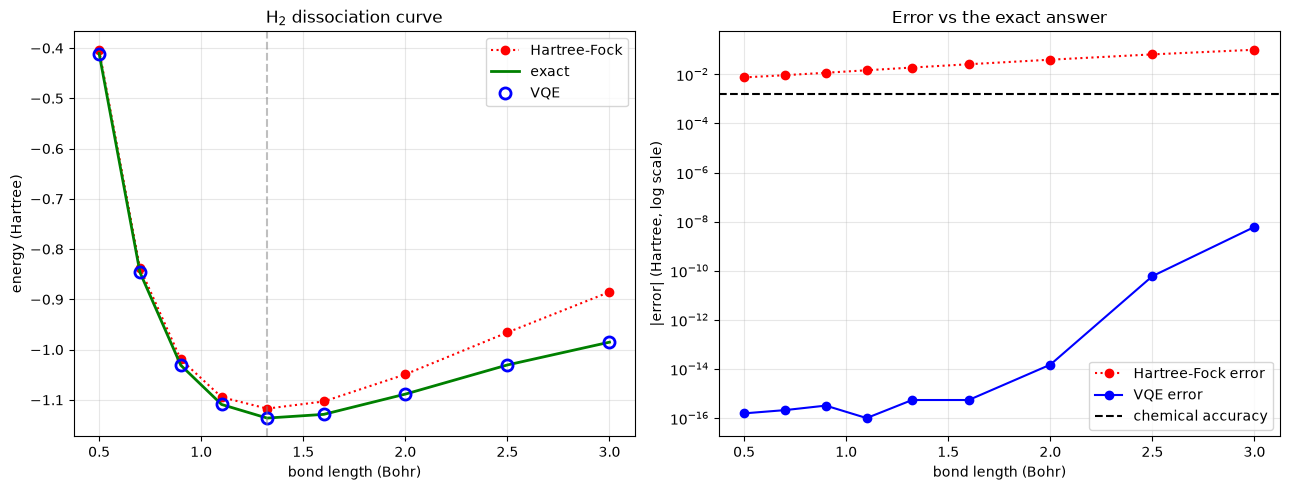

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(distances, hf_curve, 'r:o', label='Hartree-Fock')
ax1.plot(distances, exact_curve, 'g-', linewidth=2, label='exact')
ax1.plot(distances, vqe_curve, 'bo', markersize=8, fillstyle='none', markeredgewidth=2, label='VQE')
ax1.axvline(1.3228, color='gray', linestyle='--', alpha=0.5)
ax1.set_xlabel("bond length (Bohr)"); ax1.set_ylabel("energy (Hartree)")
ax1.set_title("H$_2$ dissociation curve"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.semilogy(distances, np.abs(np.array(hf_curve) - np.array(exact_curve)), 'r:o', label='Hartree-Fock error')
ax2.semilogy(distances, np.abs(np.array(vqe_curve) - np.array(exact_curve)) + 1e-16, 'b-o', label='VQE error')
ax2.axhline(1.6e-3, color='k', linestyle='--', label='chemical accuracy')
ax2.set_xlabel("bond length (Bohr)"); ax2.set_ylabel("|error| (Hartree, log scale)")
ax2.set_title("Error vs the exact answer"); ax2.legend(); ax2.grid(alpha=0.3, which='both')

plt.tight_layout(); plt.show()

#### OUTCOME :

- VQE sits **on top of** the exact curve at every bond length - the error is at machine precision,
  many orders of magnitude below chemical accuracy.
- Hartree-Fock is decent near equilibrium and then falls apart as the bond stretches. Its error at
  3 Bohr is roughly **ten times** its error at equilibrium.
- The minimum of the curve is the equilibrium bond length, and the depth of the well below the
  r → ∞ plateau is the bond dissociation energy. We computed real chemistry.

That "machine precision" agreement deserves an honest footnote : for H₂ in a minimal basis, our
one-parameter ansatz spans the *entire* relevant space, so it is exact by construction. Bigger
molecules need ansätze like **UCCSD** with many parameters, where the ansatz is no longer exact, the
optimization is genuinely hard, and barren plateaus come back. H₂ shows the method works; it does
not show the method is easy.

#### Where the real cost hides

- **Measurement.** ⟨H⟩ is a sum of Pauli terms, each needing its own measurement basis. H₂ has 15
  terms; a medium molecule has **millions**. Grouping commuting terms is an entire research area.
- **Qubit count.** Two qubits per spatial orbital. Anything industrially interesting needs hundreds
  of clean qubits.
- **Noise.** Chemical accuracy is 1.6 mHa. Look back at Problem 14 - a 3% two-qubit error rate is
  nowhere near good enough without heavy mitigation or full error correction.

#### Key Takeaways :
- VQE = the Problem 10 hybrid loop, with the energy as the loss.
- The **variational principle** guarantees you can never go below the true ground state energy.
- Chemistry-inspired ansätze sidestep barren plateaus by encoding what we already know.
- Hartree-Fock fails on stretched bonds (static correlation) - that is the target for quantum methods.

#### TASK :
1. Add a `qml.SingleExcitation` gate to the ansatz. The energy should not improve at all. Why?
   *(Hint : think about what symmetry a single excitation breaks in a closed-shell molecule.)*
2. Replace the hand-built ansatz with `qml.UCCSD`, using `qml.qchem.excitations` to generate the
   excitation lists. Count the parameters and compare the runtime.
3. Try H₃⁺ - `symbols = ["H", "H", "H"]` in a triangle with `charge=1`. How many qubits does it
   need, and does the one-parameter double-excitation ansatz still reach chemical accuracy?
4. Run the equilibrium calculation on a **shot-based** device (`qml.set_shots(circuit, shots=10000)`
   from Problem 12). How many shots do you need before you can claim chemical accuracy?